# RLHF (Reinforcement Learning from Human Feedback)


---



In [4]:
from transformers import pipeline


In [5]:
reward_name = "OpenAssistant/reward-model-deberta-v3-large-v2"

reward_pipe = pipeline("text-classification", model = reward_name)

config.json:   0%|          | 0.00/993 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.74GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/455 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

In [6]:
def get_reward_score(prompt, response):
    # Reward model input format: <prompt> [SEP] <response>
    input_text = f"{prompt} [SEP] {response}"
    score = reward_pipe(input_text)[0]['score']
    return score

In [7]:
prompt = "How can I be more productive at work?"


In [8]:
response_A = "Just stop being lazy and work harder."
response_B = "You can try techniques like Pomodoro, time-blocking, and prioritizing tasks using the Eisenhower Matrix."


In [9]:
score_A = get_reward_score(prompt, response_A)
score_B = get_reward_score(prompt, response_B)


In [10]:

print(f"Prompt: {prompt}\n")
print(f"Response A: {response_A} | Reward Score: {score_A:.4f}")
print(f"Response B: {response_B} | Reward Score: {score_B:.4f}")


Prompt: How can I be more productive at work?

Response A: Just stop being lazy and work harder. | Reward Score: -2.2880
Response B: You can try techniques like Pomodoro, time-blocking, and prioritizing tasks using the Eisenhower Matrix. | Reward Score: 4.5965


## 2. Embeddings


---



In [11]:
from transformers import AutoTokenizer, AutoModel
import torch

# 1. BERT model load karein
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

word = "apple"

# 2. Tokenize aur ID mein badlein
inputs = tokenizer(word, return_tensors="pt")

# 3. Embedding nikalna
with torch.no_grad():
    outputs = model(**inputs)
    # Sabse aakhri layer ki values (embeddings)
    embeddings = outputs.last_hidden_state

print(f"Word: {word}")
print(f"Embedding Shape: {embeddings.shape}") # Output: [1, 3, 768]
print(f"Pehle 5 numbers: {embeddings[0][1][:5]}") # Vector ke shuruati numbers

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Word: apple
Embedding Shape: torch.Size([1, 3, 768])
Pehle 5 numbers: tensor([-0.4991, -0.0349, -0.6299, -0.4701,  0.9127])


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


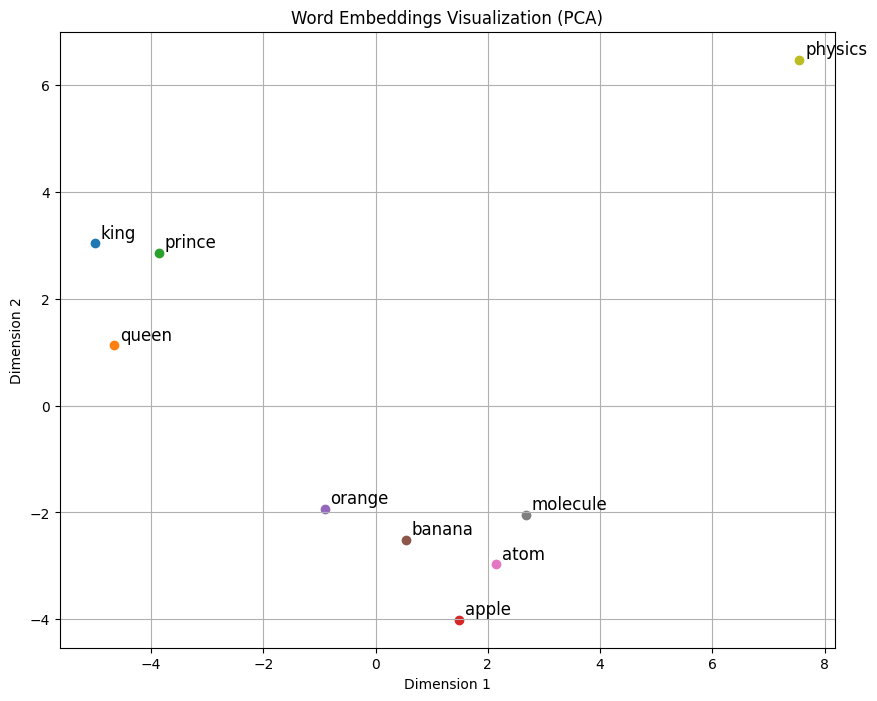

In [12]:
import torch
from transformers import AutoTokenizer, AutoModel
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np


model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)


words = ["king", "queen", "prince", "apple", "orange", "banana", "atom", "molecule", "physics"]


word_embeddings = []
for word in words:
    inputs = tokenizer(word, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)

        embedding = outputs.last_hidden_state[0, 1, :].numpy()
        word_embeddings.append(embedding)


pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(np.array(word_embeddings))


plt.figure(figsize=(10, 8))
for i, word in enumerate(words):
    plt.scatter(reduced_embeddings[i, 0], reduced_embeddings[i, 1])
    plt.annotate(word, (reduced_embeddings[i, 0] + 0.1, reduced_embeddings[i, 1] + 0.1), fontsize=12)

plt.title("Word Embeddings Visualization (PCA)")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.grid(True)
plt.show()

# Temperature and  Top-P


---






In [13]:
from transformers import pipeline

# 1. GPT-2 model
generator = pipeline('text-generation', model='gpt2')

prompt = "In a distant galaxy, humans discovered a planet made of"

# Case A: Low Temperature (Boring/Factual)

print("--- Low Temperature (0.2) ---")
res_low = generator(prompt, max_length=30, temperature=0.2, do_sample=True)
print(res_low[0]['generated_text'])

# Case B: High Temperature (Creative/Wild)

print("\n--- High Temperature (1.0) ---")
res_high = generator(prompt, max_length=30, temperature=1.0, do_sample=True)
print(res_high[0]['generated_text'])

# Case C: Low Top-P (Restricted)
print("\n--- Low Top-P (0.5) ---")
res_top_p = generator(prompt, max_length=30, top_p=0.5, do_sample=True)
print(res_top_p[0]['generated_text'])

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

--- Low Temperature (0.2) ---
In a distant galaxy, humans discovered a planet made of a single star. The planet was called the "Titan" and was the first to be

--- High Temperature (1.0) ---
In a distant galaxy, humans discovered a planet made of dark matter: It's very dark, probably only 10% as large as Earth's core.

--- Low Top-P (0.5) ---
In a distant galaxy, humans discovered a planet made of ice and water. The planet was called the "Ice Planet," and it was a planet that


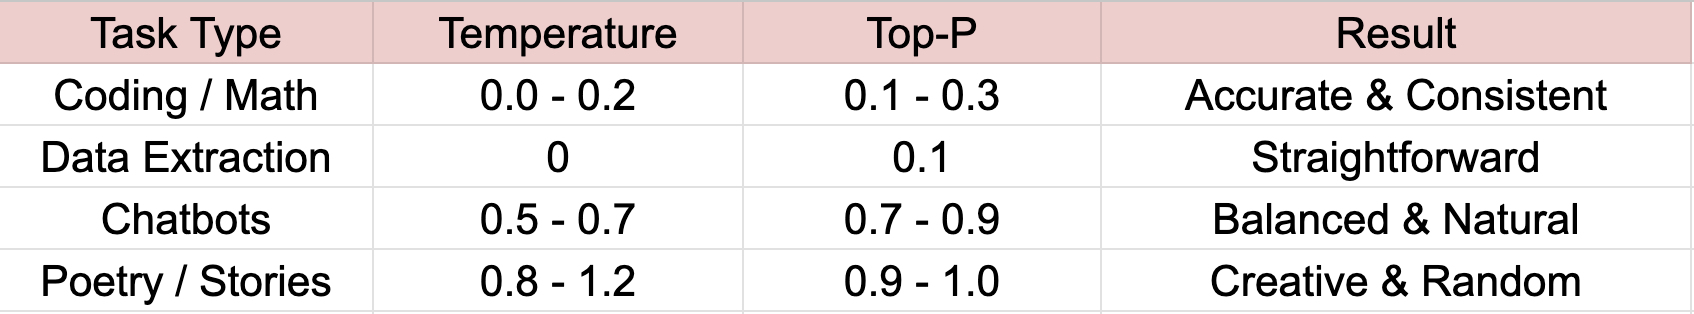

# Pre-training



---



Pre-training:
> Learning from massive, unlabeled datasets (the "Internet-scale" knowledge)

## Fine-tuning

## 2. Google Colab Implementation

In [14]:
!pip install transformers datasets accelerate evaluate

In [15]:
from datasets import load_dataset


dataset = load_dataset("stanfordnlp/imdb")


small_train_dataset = dataset["train"].shuffle(seed=42).select(range(1000))
small_eval_dataset = dataset["test"].shuffle(seed=42).select(range(1000))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [16]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

def tokenize_function(examples):
    return tokenizer(examples["text"], padding="max_length", truncation=True)

tokenized_train = small_train_dataset.map(tokenize_function, batched=True)
tokenized_test = small_eval_dataset.map(tokenize_function, batched=True)

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

**Fine-tuning**

In [17]:
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

# 1. Model Load
model = AutoModelForSequenceClassification.from_pretrained("bert-base-cased", num_labels=2)

# 2. Training Arguments
training_args = TrainingArguments(
    output_dir="test_trainer",
    eval_strategy="epoch"  # <--
)

# 3. Trainer Setup
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
)

# 4. Train
trainer.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,No log,0.345321
2,No log,0.468190
3,No log,0.575228


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=375, training_loss=0.3344463094075521, metrics={'train_runtime': 399.6073, 'train_samples_per_second': 7.507, 'train_steps_per_second': 0.938, 'total_flos': 789333166080000.0, 'train_loss': 0.3344463094075521, 'epoch': 3.0})

In [18]:
from transformers import pipeline


classifier = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)


test_text = "This movie was an absolute masterpiece, the acting was top-notch!"
result = classifier(test_text)

print(f"Text: {test_text}")
print(f"Result: {result}")

Text: This movie was an absolute masterpiece, the acting was top-notch!
Result: [{'label': 'LABEL_1', 'score': 0.9984037280082703}]


In [19]:
model.save_pretrained("/content/sentiment_model")
tokenizer.save_pretrained("/content/sentiment_model")

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [30]:
import os

folder = "/content/sentiment_model"

print("Files:", os.listdir(folder))

size = sum(
    os.path.getsize(os.path.join(folder, f))
    for f in os.listdir(folder)
    if os.path.isfile(os.path.join(folder, f))
)

print(f"Model size: {size / (1024**2):.2f} MB")

Files: ['config.json', 'tokenizer.json', 'tokenizer_config.json', 'model.safetensors']
Model size: 413.84 MB


In [20]:
!pip install -q fastapi nest-asyncio uvicorn pyngrok

In [21]:
import nest_asyncio
from fastapi import FastAPI
from fastapi.middleware.cors import CORSMiddleware
from pydantic import BaseModel
from pyngrok import ngrok
import uvicorn

app = FastAPI()

# Enable CORS so our React frontend can send requests to the backend
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_credentials=True,
    allow_methods=["*"],
    allow_headers=["*"],
)

class TextRequest(BaseModel):
    text: str

# Welcome route to prevent 404 errors when opening the URL directly
@app.get("/")
def read_root():
    return {"status": "Server is up and running successfully! Use /predict to run sentiment analysis."}

@app.post("/predict")
def predict(request: TextRequest):
    prediction = classifier(request.text)[0]
    label = prediction['label']
    score = prediction['score']

    # Map label to friendly output
    sentiment = "Positive" if label == "LABEL_1" else "Negative"
    return {"sentiment": sentiment, "confidence": float(score)}

In [31]:
!pip install -q huggingface_hub


In [32]:
from huggingface_hub import login
from getpass import getpass

token = getpass("Enter your Hugging Face token: ")
login(token=token)

print("Successfully logged in!")

Enter your Hugging Face token: ··········
Successfully logged in!


In [34]:
from huggingface_hub import HfApi

api = HfApi()

api.upload_folder(
    folder_path="/content/sentiment_model",
    repo_id="slsourav005/movie-sentiment",
    repo_type="model"
)

print("Model uploaded successfully!")

Model uploaded successfully!


### 2. Create the React Frontend
We will now write a single-file React application (`index.html`) using React and Tailwind CSS via CDNs.

In [22]:
react_html_content = """
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>BERT Sentiment Analyzer</title>
    <!-- Tailwind CSS for styling -->
    <script src="https://cdn.tailwindcss.com"></script>
    <!-- React and Babel CDNs -->
    <script src="https://unpkg.com/react@18/umd/react.development.js" crossorigin></script>
    <script src="https://unpkg.com/react-dom@18/umd/react-dom.development.js" crossorigin></script>
    <script src="https://unpkg.com/@babel/standalone/babel.min.js"></script>
</head>
<body class="bg-gray-900 text-gray-100 min-h-screen flex items-center justify-center font-sans">

    <div id="root"></div>

    <script type="text/babel">
        const { useState } = React;

        function App() {
            const [text, setText] = useState('');
            const [result, setResult] = useState(null);
            const [loading, setLoading] = useState(false);
            const [backendUrl, setBackendUrl] = useState('');

            const handlePredict = async () => {
                if (!backendUrl) {
                    alert("Please paste your Colab Backend URL first!");
                    return;
                }
                if (!text) {
                    alert("Please enter some text.");
                    return;
                }
                setLoading(true);
                setResult(null);
                try {
                    const cleanUrl = backendUrl.replace(/\/$/, '');
                    const response = await fetch(`${cleanUrl}/predict`, {
                        method: 'POST',
                        headers: {
                            'Content-Type': 'application/json',
                            'Bypass-Tunnel-Reminder': 'true'
                        },
                        body: JSON.stringify({ text }),
                    });
                    const data = await response.json();
                    setResult(data);
                } catch (error) {
                    console.error("Error sending request:", error);
                    alert("Failed to connect to backend.\n\nFix:\n1. Make sure you ran the backend cell inside Colab.\n2. Open the Backend URL in a new tab first, click 'Proceed' or 'Bypass' if a warning shows up, then try again here!");
                }
                setLoading(false);
            };

            return (
                <div class="bg-gray-800 p-8 rounded-2xl shadow-2xl max-w-lg w-full mx-4 border border-gray-700">
                    <h1 class="text-3xl font-extrabold text-transparent bg-clip-text bg-gradient-to-r from-teal-400 to-blue-500 mb-2 text-center">
                        BERT Sentiment Analysis
                    </h1>
                    <p class="text-gray-400 text-sm mb-6 text-center">
                        Enter text to analyze sentiment powered by React & FastAPI
                    </p>

                    <div class="mb-4">
                        <label class="block text-xs font-semibold uppercase tracking-wider text-gray-400 mb-2">
                            1. Colab Backend URL
                        </label>
                        <input
                            type="text"
                            value={backendUrl}
                            onChange={(e) => setBackendUrl(e.target.value)}
                            placeholder="https://xxxx-colab.googleusercontent.com"
                            class="w-full p-3 bg-gray-900 border border-gray-700 rounded-lg text-sm text-teal-300 focus:outline-none focus:ring-2 focus:ring-teal-500"
                        />
                        <p class="text-xs text-amber-400 mt-1">
                          ⚠️ First-time run? Open the URL in a new tab to authorize/activate the connection before typing here.
                        </p>
                    </div>

                    <div class="mb-6">
                        <label class="block text-xs font-semibold uppercase tracking-wider text-gray-400 mb-2">
                            2. Movie Review / Sentence
                        </label>
                        <textarea
                            rows="4"
                            value={text}
                            onChange={(e) => setText(e.target.value)}
                            placeholder="Type here... (e.g., 'The screenplay was absolutely brilliant!')"
                            class="w-full p-3 bg-gray-900 border border-gray-700 rounded-lg text-sm focus:outline-none focus:ring-2 focus:ring-teal-500"
                        />
                    </div>

                    <button
                        onClick={handlePredict}
                        disabled={loading}
                        class="w-full py-3 bg-gradient-to-r from-teal-500 to-blue-600 hover:from-teal-400 hover:to-blue-500 font-bold rounded-lg transition-all transform active:scale-95 disabled:opacity-50"
                    >
                        {loading ? 'Analyzing...' : 'Analyze Sentiment'}
                    </button>

                    {result && (
                        <div class="mt-6 p-4 rounded-lg bg-gray-900 border border-gray-700 animate-fade-in">
                            <div class="text-xs text-gray-400 uppercase font-semibold tracking-wider mb-2">Analysis Result:</div>
                            <div class="flex justify-between items-center">
                                <span class="text-lg font-bold">
                                    Sentiment:
                                    <span class={result.sentiment === 'Positive' ? 'text-green-400 ml-2' : 'text-red-400 ml-2'}>
                                        {result.sentiment} {result.sentiment === 'Positive' ? '😄' : '😞'}
                                    </span>
                                </span>
                                <span class="text-sm text-gray-400">
                                    Confidence: {(result.confidence * 100).toFixed(2)}%
                                </span>
                            </div>
                        </div>
                    )}
                </div>
            );
        }

        const root = ReactDOM.createRoot(document.getElementById('root'));
        root.render(<App />);
    </script>
</body>
</html>
"""

with open("index.html", "w") as f:
    f.write(react_html_content)

print("React Webpage 'index.html' has been updated with proxy configurations!")

React Webpage 'index.html' has been updated with proxy configurations!


<>:40: SyntaxWarning: invalid escape sequence '\/'
<>:40: SyntaxWarning: invalid escape sequence '\/'
/tmp/ipykernel_567/3939686264.py:40: SyntaxWarning: invalid escape sequence '\/'
  const cleanUrl = backendUrl.replace(/\/$/, '');


In [23]:
from google.colab import output
import nest_asyncio
import uvicorn
import threading

# Configure Nest Asyncio to allow nested event loops
nest_asyncio.apply()

# Correctly generate the secure public proxy URL using Colab's Javascript helper
public_url = output.eval_js("google.colab.kernel.proxyPort(8000)")
print(f"* Backend Public URL: {public_url}")
print("-> Copy this URL and paste it into the 'Colab Backend URL' field in your React webpage.")

def run_server():
    # Use the 'app' defined in cell 25c99180 which now contains the root route
    config = uvicorn.Config(app, host="127.0.0.1", port=8000, log_level="info")
    server = uvicorn.Server(config)
    server.run()

# Run the server in a separate daemon thread so it doesn't block the Jupyter cell
server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()
print("Server has been restarted successfully in the background!")

* Backend Public URL: https://8000-gpu-t4-s-ass1a0-989tiqpt1zo0-a.asia-southeast1.prod.r.colab.dev
-> Copy this URL and paste it into the 'Colab Backend URL' field in your React webpage.
Server has been restarted successfully in the background!


In [24]:
import urllib.request
# Get our public IP address which Localtunnel uses as a password for first-time verification
print("Your Localtunnel Password (IP Address) is:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

Your Localtunnel Password (IP Address) is: 34.143.172.126


In [25]:
# Install localtunnel globally
!npm install -g localtunnel

INFO:     Started server process [567]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼
added 22 packages in 5s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼

In [26]:
import subprocess
import time

# Start localtunnel on port 8000 in the background
lt_process = subprocess.Popen(["lt", "--port", "8000"], stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)

# Give localtunnel a few seconds to establish the connection
time.sleep(5)

# Read and print the generated public URL
print("--- Localtunnel Output ---")
for _ in range(3):
    line = lt_process.stdout.readline()
    if "your url is" in line:
        print("\nSUCCESS! Your fully functional Backend URL is:")
        print(line.strip().replace("your url is: ", ""))
        print("\nInstructions:\n1. Click that link above first.\n2. If it asks for an IP/Password, paste the IP Address printed in the previous cell and click 'Click to Submit'.\n3. Paste that same URL into your index.html text box, and it will work perfectly!")
        break

--- Localtunnel Output ---

SUCCESS! Your fully functional Backend URL is:
https://wet-actors-attack.loca.lt

Instructions:
1. Click that link above first.
2. If it asks for an IP/Password, paste the IP Address printed in the previous cell and click 'Click to Submit'.
3. Paste that same URL into your index.html text box, and it will work perfectly!


In [27]:
# 1. Download and install Cloudflare Tunnel
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb

Selecting previously unselected package cloudflared.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack cloudflared-linux-amd64.deb ...
Unpacking cloudflared (2026.10.7) ...
Setting up cloudflared (2026.10.7) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [28]:
import subprocess
import time
import re

# 2. Start cloudflared tunnel pointing to our FastAPI server on port 8000
cf_process = subprocess.Popen(["cloudflared", "tunnel", "--url", "http://127.0.0.1:8000"],
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)

# Wait for tunnel initialization and retrieve the trycloudflare public URL
cf_url = None
time.sleep(6)

# Scan the logs for the generated .trycloudflare.com URL
for i in range(50):
    line = cf_process.stdout.readline()
    match = re.search(r'https://[a-zA-Z0-9-]+\.trycloudflare\.com', line)
    if match:
        cf_url = match.group(0)
        break

if cf_url:
    print("\n=========================================================")
    print("🔥 SUCCESS! YOUR PERMANENT WORKING BACKEND URL IS:")
    print(cf_url)
    print("=========================================================")
    print("\n👉 INSTRUCTIONS:")
    print(f"1. Copy this link: {cf_url}")
    print("2. Paste it directly into the 'Colab Backend URL' input box in your React web page (index.html).")
    print("3. Type your text, click 'Analyze Sentiment', and it will work immediately!")
else:
    print("Tunnel setup timed out. Please try running this cell again.")


🔥 SUCCESS! YOUR PERMANENT WORKING BACKEND URL IS:
https://chargers-focus-missile-julie.trycloudflare.com

👉 INSTRUCTIONS:
1. Copy this link: https://chargers-focus-missile-julie.trycloudflare.com
2. Paste it directly into the 'Colab Backend URL' input box in your React web page (index.html).
3. Type your text, click 'Analyze Sentiment', and it will work immediately!
